In [28]:
import json
import numpy as np
import trimesh
import cv2
import matplotlib.pyplot as plt
import torch
import os
import logging
import torch
import hydra
import sys
from hydra import compose, initialize
from omegaconf import OmegaConf
import torch.nn.functional as F
from sklearn.decomposition import PCA
import objaverse


os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["HYDRA_FULL_ERROR"] = "1" # Debug

# DINO
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


In [29]:
import objaverse

UID = "04ab56ff7f5044629e424a6fcb871b76"        # Polipetto
UID =  "026dfb57bcb5406688a7b20dfbecc6c2"    # chiave
#UID = "0292b47486774a538c0f891605c7bda1"    # Macchinina
#UID = "01ab7318c6f748569ee683ea13ba78c0"   # Chitarra
objects = objaverse.load_objects(
    uids=[UID],
    download_processes=1
)

GLB_PATH = objects[UID]
print(f"Oggetto scaricato in: {GLB_PATH}")

Oggetto scaricato in: /home/riccardop02/.objaverse/hf-objaverse-v1/glbs/000-023/026dfb57bcb5406688a7b20dfbecc6c2.glb


In [30]:
loaded = trimesh.load(GLB_PATH)  # SENZA force="mesh", per ispezionare
if isinstance(loaded, trimesh.Scene):
    print("n. geometrie:", len(loaded.geometry))
    for name, geom in loaded.geometry.items():
        mat = getattr(geom.visual, "material", None)
        print(name, type(geom.visual), getattr(mat, "name", mat))

        

n. geometrie: 1
Object_0 <class 'trimesh.visual.texture.TextureVisuals'> Material.007


# Create The model

In [31]:
# Utilities
def load_mesh(model_path: str) -> trimesh.Trimesh:
    loaded = trimesh.load(model_path, force="mesh")

    if isinstance(loaded, trimesh.Scene):
        if len(loaded.geometry) == 0:
            raise ValueError(f"Nessuna geometria trovata in: {model_path}")
        mesh = loaded.dump(concatenate=True)
    else:
        mesh = loaded

    if not isinstance(mesh, trimesh.Trimesh):
        raise TypeError(f"Tipo mesh non supportato dopo il caricamento: {type(mesh)}")

    return mesh


def sample_pointcloud_with_color(mesh: trimesh.Trimesh, n_points: int) -> np.ndarray:
    """
    Campiona n_points sulla superficie della mesh e assegna il colore
    interpolando la UV map sulla texture.
    Ritorna (n_points, 6): xyz grezzo + rgb in [0, 255].
    """
    # Campiona punti sulla superficie; face_idx dice da quale triangolo viene ogni punto
    points, face_idx = trimesh.sample.sample_surface(mesh, n_points)

    # Coordinate baricentriche di ogni punto rispetto al suo triangolo
    triangles = mesh.triangles[face_idx]              # (n_points, 3, 3)
    bary = trimesh.triangles.points_to_barycentric(triangles, points)  # (n_points, 3)

    # UV dei 3 vertici di ogni triangolo campionato
    uv_all = mesh.visual.uv                            # (N_vertices, 2)
    face_uv = uv_all[mesh.faces[face_idx]]              # (n_points, 3, 2)

    # Interpola la UV nel punto usando le coordinate baricentriche
    point_uv = np.einsum('ij,ijk->ik', bary, face_uv)   # (n_points, 2)

    # DEF
    def get_texture_image(material):
        # Caso PBRMaterial (tipico glTF/glb)
        if hasattr(material, "baseColorTexture") and material.baseColorTexture is not None:
            return np.array(material.baseColorTexture.convert("RGB"))
        # Caso SimpleMaterial (tipico obj)
        if hasattr(material, "image") and material.image is not None:
            return np.array(material.image.convert("RGB"))
        raise AttributeError(
            f"Materiale di tipo {type(material)} non ha una texture immagine valida "
            f"(né baseColorTexture né image)."
        )


    # Campiona la texture in quelle coordinate UV
    texture_img = get_texture_image(mesh.visual.material)
    tex_h, tex_w = texture_img.shape[:2]

    u_px = np.clip((point_uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
    v_px = np.clip(((1 - point_uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)

    colors = texture_img[v_px, u_px].astype(np.float32)  # (n_points, 3), in [0, 255]

    return np.concatenate([points, colors], axis=-1).astype(np.float32)  # (n_points, 6)


def normalize_pointcloud(pc: np.ndarray) -> np.ndarray:
    """
    pc: (N, 6) con xyz grezzo e rgb in [0, 255].
    Ritorna (N, 6) con xyz in sfera unitaria e rgb in [-1, 1].
    """
    xyz = pc[:, :3].copy()
    rgb = pc[:, 3:].copy()

    centroid = xyz.mean(axis=0, keepdims=True)
    xyz = xyz - centroid
    scale = np.max(np.linalg.norm(xyz, axis=1))
    if scale > 0:
        xyz = xyz / scale

    rgb = (rgb / 255.0 - 0.5) / 0.5

    return np.concatenate([xyz, rgb], axis=-1).astype(np.float32), centroid, scale


def process_single_object(model_path: str, encoder3d, n_points: int, device: torch.device):
    """Versione single-object di process_model, per test rapido su Object 20."""
    mesh = load_mesh(model_path)
    pc = sample_pointcloud_with_color(mesh, n_points)
    import trimesh
    cloud = trimesh.points.PointCloud(pc[:, :3], colors=pc[:, 3:].astype(np.uint8))
    cloud.export("/data/riccardop02/renders/debug_pc.ply")
    pc, centroid, scale = normalize_pointcloud(pc)

    pc_tensor = torch.from_numpy(pc).unsqueeze(0).to(device)  # (1, N, 6)

    with torch.no_grad():
        feats, centers = encoder3d.extractFeatures(pc_tensor)

    return feats.squeeze(0).cpu().numpy(), centers.squeeze(0).cpu().numpy(), centroid.squeeze(), scale

def _generate_rays(K, R, trans, centroid, scale, grid_size=16, patch_size=14):
        """
        Plucker rays, normalized by centroid and scale of the 3D model.
        """
        B = K.shape[0]
        device = K.device

        y = torch.arange(grid_size, device=device, dtype=torch.float32)
        x = torch.arange(grid_size, device=device, dtype=torch.float32)
        grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')

        u = grid_x * patch_size + (patch_size / 2.0)
        v = grid_y * patch_size + (patch_size / 2.0)

        uv1 = torch.stack([u, v, torch.ones_like(u)], dim=-1).reshape(-1, 3)
        uv1 = uv1.unsqueeze(0).expand(B, -1, -1)

        K_inv = torch.linalg.inv(K)
        d_c = torch.bmm(uv1, K_inv.transpose(1, 2))

        R_inv = R.transpose(1, 2)
        d_o = F.normalize(torch.bmm(d_c, R_inv.transpose(1, 2)), p=2, dim=-1)   # (B, N, 3)

       
        centroid_col = centroid.unsqueeze(-1)                                            # (B, 3, 1)
        trans_norm = (trans.unsqueeze(-1) + torch.bmm(R, centroid_col)).squeeze(-1)      # (B, 3)
        trans_norm = trans_norm / scale.unsqueeze(-1)                                    # (B, 3)

        O = -torch.bmm(R_inv, trans_norm.unsqueeze(-1)).squeeze(-1)                      # (B, 3)
        O_exp = O.unsqueeze(1).expand(-1, d_o.shape[1], -1)
        moment = torch.cross(O_exp, d_o, dim=-1)                                         # (B, N, 3)

        return d_o, moment

def masked_l1_per_sample(pred_tensor, targ_tensor, mask_tensor):
    """Restituisce la L1 mascherata per ogni elemento del batch: shape (B,)"""
    err = F.l1_loss(pred_tensor, targ_tensor, reduction='none').mean(dim=-1)  # (B, N)
    valid = mask_tensor.float()
    return (err * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)


In [32]:
# Instatiate the model

sys.path.insert(0, "/home/riccardop02/JEPA")

logging.basicConfig(level=logging.INFO)
log = logging.getLogger(__name__)

# --- Config ---
with initialize(version_base=None, config_path="../../configs"):
    cfg = compose(config_name="config")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Only for the UNI3D
cfg.encoder3d['ckpt_path'] = "/home/riccardop02/JEPA/weights/model.pt"

# --- Istanzia i modelli ---
encoder2d = hydra.utils.instantiate(cfg.encoder2d)
encoder3d = hydra.utils.instantiate(cfg.encoder3d)
encoder2d.to(device)
encoder3d.to(device)
log.info("Dino Initialized...")
log.info(f"Encoder2d: {type(encoder2d)}, output_dim: {encoder2d.output_dim}, "
          f"layers: {encoder2d.layers}, token: {encoder2d.token}")
log.info(f"Encoder3d: {type(encoder3d)}, output_dim: {encoder3d.output_dim}")

predictor = hydra.utils.instantiate(
    cfg.Predictor,
    context_dim=encoder3d.output_dim[0][-1],
    output_dim=encoder2d.output_dim[-1]
)
predictor.to(device)

# predictor appena inizializzato (pesi random), per confronto/test strutturale
predictor_init = hydra.utils.instantiate(
    cfg.Predictor, context_dim=encoder3d.output_dim[0][-1], output_dim=encoder2d.output_dim[-1]
).to(device)
predictor_init.eval()

# --- Carica checkpoint ---
PATH_CHECK = '/experiments/riccardop02/outputs/2026-09-09/15-03-54/checkpoints/best.pt' 
checkpoint = torch.load(PATH_CHECK, map_location=device, weights_only=False)

encoder2d.load_state_dict(checkpoint["models"]['encoder2d'])
predictor.load_state_dict(checkpoint["models"]['predictor'])
encoder3d.load_state_dict(checkpoint["models"]['encoder3d'])

encoder2d.eval()
predictor.eval()
encoder3d.eval()
log.info(f"Checkpoint loaded from {PATH_CHECK}, epoch {checkpoint['epoch']}")




INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/resolve/main/preprocessor_config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/facebook/dinov2-base/f9e44c814b77203eaa57a6bdbbd535f21ede1415/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov2-base/

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

INFO:root:Uni3D constructed, loading Uni3D weights from /home/riccardop02/JEPA/weights/model.pt ...
INFO:__main__:Dino Initialized...
INFO:__main__:Encoder2d: <class 'src.models.encoder2d.DINOv2.DINOv2'>, output_dim: torch.Size([256, 768]), layers: [9], token: PatchToken
INFO:__main__:Encoder3d: <class 'src.models.encoder3d.Uni3D.Uni3DEncoder'>, output_dim: ((1, 512, 768), (1, 512, 3))
--- Logging error ---
Traceback (most recent call last):
  File "/home/riccardop02/miniconda3/envs/poseJepa/lib/python3.11/logging/__init__.py", line 1110, in emit
    msg = self.format(record)
          ^^^^^^^^^^^^^^^^^^^
  File "/home/riccardop02/miniconda3/envs/poseJepa/lib/python3.11/logging/__init__.py", line 953, in format
    return fmt.format(record)
           ^^^^^^^^^^^^^^^^^^
  File "/home/riccardop02/miniconda3/envs/poseJepa/lib/python3.11/logging/__init__.py", line 687, in format
    record.message = record.getMessage()
                     ^^^^^^^^^^^^^^^^^^^
  File "/home/riccardop02/min

In [33]:
# compute feature of the object
feats3d, centers, centroid, scale = process_single_object(GLB_PATH, encoder3d, n_points=8192, device=device)

log.info(f"3D features: {feats3d.shape}, centers: {centers.shape}")


INFO:__main__:3D features: (512, 768), centers: (512, 3)


In [34]:
os.environ["PYOPENGL_PLATFORM"] = "osmesa"  # rendering offscreen headless
import pyrender

N_VIEW = 36
IMG_SIZE = 224
CAM_DIST = 2.0          # distanza in spazio NORMALIZZATO (quella con cui è stato allenato il modello)
FOV_Y = np.pi / 3.0

# --- Carica la mesh RAW, SENZA normalizzarla ---
scene_trimesh = trimesh.load(GLB_PATH, force="scene")
mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh
# NIENTE mesh_tm.vertices -= ... / *= ... qui: usiamo le coordinate raw,
# centroid/scale (calcolati sopra da process_single_object) faranno da convertitore

mesh = pyrender.Mesh.from_trimesh(mesh_tm, smooth=False)

# --- Distanza camera in unità RAW, coerente con lo `scale` del point cloud ---
CAM_DIST_RAW = CAM_DIST * scale

# --- Intrinseca (costante per tutte le viste) ---
def get_intrinsics(width, height, fov_y):
    f = height / (2 * np.tan(fov_y / 2))
    cx, cy = width / 2, height / 2
    return np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]], dtype=np.float32)

K = get_intrinsics(IMG_SIZE, IMG_SIZE, FOV_Y)

renderer = pyrender.OffscreenRenderer(IMG_SIZE, IMG_SIZE)
camera = pyrender.PerspectiveCamera(yfov=FOV_Y, aspectRatio=1.0)
light = pyrender.DirectionalLight(color=np.ones(3), intensity=3.0)

# --- Look-at coerente con la convenzione di training (OpenCV: +Z forward, Y down) ---
def look_at_opencv(eye, target=np.array([0.0, 0.0, 0.0]), world_up=np.array([0.0, 1.0, 0.0])):
    """
    Ritorna:
      R_w2c : (3,3) rotazione world-to-camera, convenzione OpenCV
      t_w2c : (3,)  traslazione world-to-camera coerente con R_w2c
      cam_pose_gl : (4,4) posa camera-to-world in convenzione OpenGL, per pyrender
    """
    forward = target - eye
    forward = forward / np.linalg.norm(forward)

    right = np.cross(forward, world_up)
    right = right / np.linalg.norm(right)
    up = np.cross(right, forward)

    R_cam_to_world = np.stack([right, -up, forward], axis=1)
    R_w2c = R_cam_to_world.T
    t_w2c = -R_w2c @ eye

    cam_pose_gl = np.eye(4)
    cam_pose_gl[:3, :3] = R_cam_to_world
    cam_pose_gl[:3, 3] = eye
    cv_to_gl = np.diag([1.0, -1.0, -1.0, 1.0])
    cam_pose_gl = cam_pose_gl @ cv_to_gl

    return R_w2c.astype(np.float32), t_w2c.astype(np.float32), cam_pose_gl


# --- Dizionario principale: view_id -> {rgb, mask, K, R, ...} ---
render_data = {}

for i in range(N_VIEW):
    theta = 2 * np.pi * i / N_VIEW
    phi = np.pi / 4

    direction = np.array([
        np.cos(theta) * np.sin(phi),
        np.cos(phi),
        np.sin(theta) * np.sin(phi)
    ])
    eye = centroid + CAM_DIST_RAW * direction   # <-- orbita attorno al centroid, in unità raw

    R_pose, T_cam, cam_pose = look_at_opencv(eye, target=centroid)  # <-- guarda verso centroid

    scene = pyrender.Scene(bg_color=[0, 0, 0, 1.0], ambient_light=[0.3, 0.3, 0.3])
    scene.add(mesh)
    scene.add(camera, pose=cam_pose)
    scene.add(light, pose=cam_pose)

    color, depth = renderer.render(scene, flags=pyrender.RenderFlags.RGBA)

    render_data[i] = {
        "rgb": color[..., :3],
        "mask": (depth > 0).astype(np.uint8) * 255,
        "K": K,
        "R_pose": R_pose,
        "eye": eye,
        "T_cam": T_cam,
        "theta": theta,
        "phi": phi,
    }

renderer.delete()

print(f"Renderizzate {N_VIEW} viste, salvate in memoria in `render_data`.")

/tmp/ipykernel_630785/2928102496.py:11: DeprecationWarning: `Scene.dump(concatenate=True)` DEPRECATED FOR REMOVAL APRIL 2025: replace with `Scene.to_geometry()`
  mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh


Renderizzate 36 viste, salvate in memoria in `render_data`.




In [35]:
#Plotting each view and the mask
fig, axes = plt.subplots(N_VIEW, 2, figsize=(6, 3 * N_VIEW))

for i in range(N_VIEW):
    axes[i, 0].imshow(render_data[i]["rgb"])
    axes[i, 0].set_title(f"View {i} - RGB")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(render_data[i]["mask"], cmap="gray")
    axes[i, 1].set_title(f"View {i} - Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [36]:
from PIL import Image as PILImage

def pixel_mask_to_token_mask(mask, grid_size=16):
    mask_pil = PILImage.fromarray((mask.astype(np.uint8)) * 255 if mask.max() <= 1 else mask.astype(np.uint8))
    mask_grid = mask_pil.resize((grid_size, grid_size), PILImage.BOX)
    return np.array(mask_grid, dtype=np.float32) / 255.0  # valori continui [0,1]

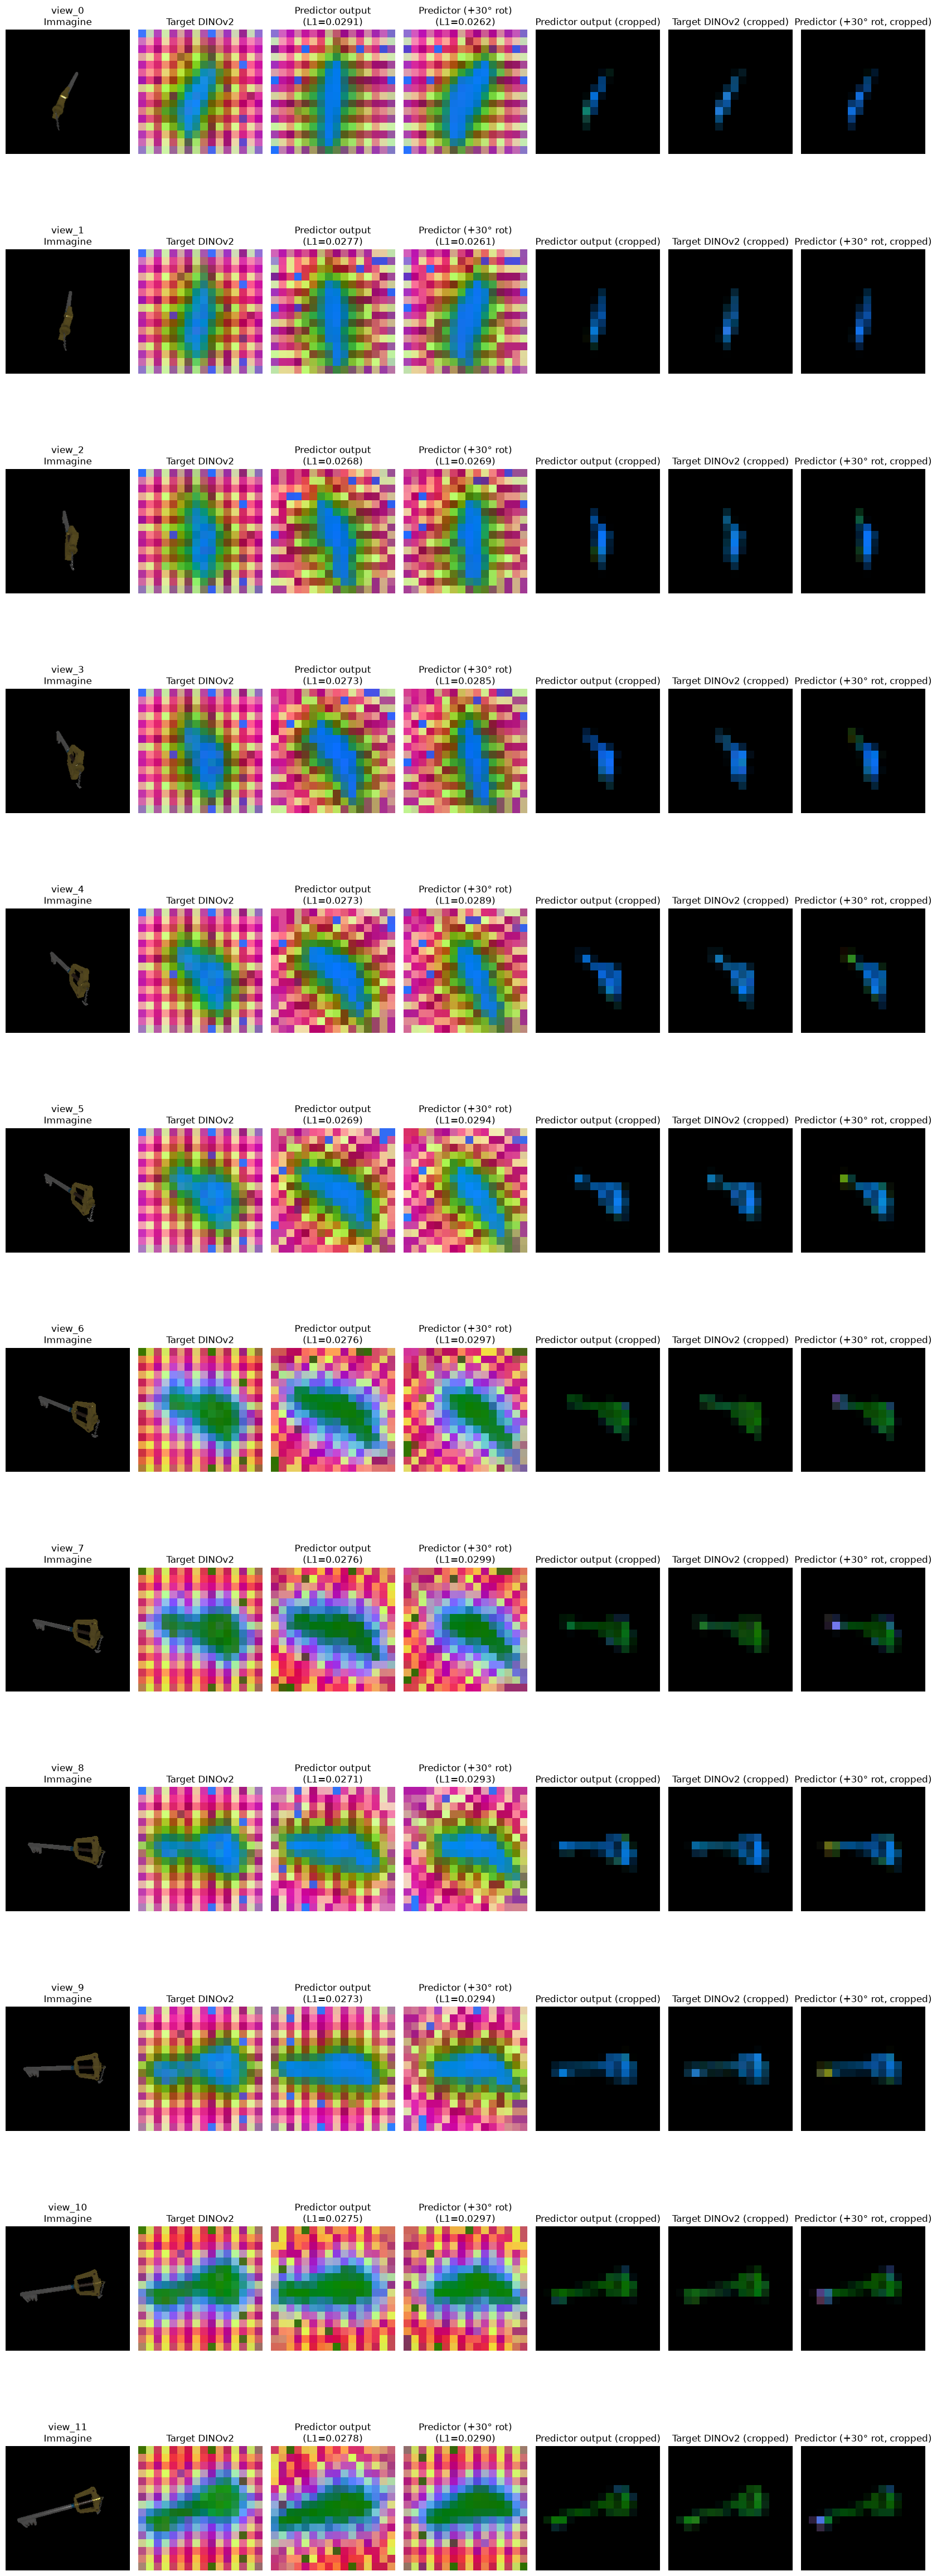

In [37]:
from sklearn.decomposition import PCA

N_OBJECTS = min(12, len(render_data))
GRID_SIZE = 16
WRONG_ROT_DEG = 30.0  # gradi di rotazione errata da aggiungere

MEAN_t = torch.tensor(MEAN, dtype=torch.float32, device=device).view(1, 3, 1, 1)
STD_t = torch.tensor(STD, dtype=torch.float32, device=device).view(1, 3, 1, 1)

context_t = torch.from_numpy(feats3d).unsqueeze(0).to(device)
centers_t = torch.from_numpy(centers).unsqueeze(0).to(device)

def to_rgb_map_local(pca_tokens, grid_size=GRID_SIZE):
    """Normalizzazione min/max LOCALE, calcolata solo sui token passati (come nello script di validation)."""
    vmin = pca_tokens.min(axis=0, keepdims=True)
    vmax = pca_tokens.max(axis=0, keepdims=True)
    norm = (pca_tokens - vmin) / (vmax - vmin + 1e-8)
    norm = np.clip(norm, 0, 1)
    return norm.reshape(grid_size, grid_size, 3)

def rotation_matrix(axis, deg, device):
    """Matrice di rotazione 3x3 attorno a un asse ('x', 'y' o 'z')."""
    rad = np.deg2rad(deg)
    c, s = np.cos(rad), np.sin(rad)
    if axis == 'x':
        R = np.array([[1, 0, 0],
                      [0, c, -s],
                      [0, s,  c]], dtype=np.float32)
    elif axis == 'y':
        R = np.array([[ c, 0, s],
                      [ 0, 1, 0],
                      [-s, 0, c]], dtype=np.float32)
    elif axis == 'z':
        R = np.array([[c, -s, 0],
                      [s,  c, 0],
                      [0,  0, 1]], dtype=np.float32)
    else:
        raise ValueError("axis deve essere 'x', 'y' o 'z'")
    return torch.from_numpy(R).to(device)

R_offset = rotation_matrix('y', WRONG_ROT_DEG, device)  # <-- cambia asse se serve

view_ids = list(render_data.keys())[:N_OBJECTS]

fig, axes = plt.subplots(N_OBJECTS, 7, figsize=(16.8, 4 * N_OBJECTS))
if N_OBJECTS == 1:
    axes = axes[None, :]

for i, vid in enumerate(view_ids):
    view = render_data[vid]

    img_np = view["rgb"].astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device)
    img_t = (img_t - MEAN_t) / STD_t

    mask_t = torch.from_numpy(view["mask"].astype(np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(device)

    K_t = torch.from_numpy(view["K"]).unsqueeze(0).to(device).float()
    # R world-to-camera corretta: è R_pose, non R_cam (che è camera-to-world)
    rot_t = torch.from_numpy(view["R_pose"]).unsqueeze(0).to(device).float()
    trans_t = torch.from_numpy(view["T_cam"]).unsqueeze(0).to(device).float()

    rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)
    token_mask_np = pixel_mask_to_token_mask(view["mask"], grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np.reshape(-1)).float().unsqueeze(0).to(device)
    

    mask_t = torch.from_numpy(token_mask_np.reshape(-1)).float().unsqueeze(0).to(device)

    centroid_t = torch.from_numpy(centroid).unsqueeze(0).to(device).float()   # (1, 3)
    scale_t = torch.tensor([scale], device=device).float()      

    ray_dirs, moment_c = _generate_rays(K_t, rot_t, trans_t, centroid_t, scale_t)
    ray_dirs_wrong, moment_wrong = _generate_rays(K_t, rot_wrong_t, trans_t, centroid_t, scale_t)

    with torch.no_grad():
        target = encoder2d(img_t)
        pred = predictor(
            ray_dirs=ray_dirs,
            ray_moments=moment_c,
            context_features=context_t,
            context_centers=centers_t,
        )
        pred_wrong = predictor(
            ray_dirs=ray_dirs_wrong,
            ray_moments=moment_wrong,
            context_features=context_t,
            context_centers=centers_t,
        )
        l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
        l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()


    target_np = target.squeeze(0).cpu().numpy()          # (256, 768)
    pred_np = pred.squeeze(0).cpu().numpy()               # (256, 768)
    pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()    # (256, 768)

    # --- PCA fittata SOLO sul target di QUESTA vista ---
    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    pred_pca = pca.transform(pred_np)
    pred_wrong_pca = pca.transform(pred_wrong_np)  # stessa PCA del target, come richiesto

    # --- Normalizzazione min/max LOCALE ---
    target_map = to_rgb_map_local(target_pca)
    pred_map = to_rgb_map_local(pred_pca)
    pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"view_{vid}\nImmagine")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_map)
    axes[i, 2].set_title(f"Predictor output\n(L1={l1_pred:.4f})")
    axes[i, 2].axis('off')

    axes[i, 3].imshow(pred_wrong_map)
    axes[i, 3].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot)\n(L1={l1_pred_wrong:.4f})")
    axes[i, 3].axis('off')

    axes[i, 4].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 4].set_title("Predictor output (cropped)")
    axes[i, 4].axis('off')

    axes[i, 5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 5].set_title("Target DINOv2 (cropped)")
    axes[i, 5].axis('off')


    axes[i, 6].imshow(pred_wrong_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 6].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot, cropped)")
    axes[i, 6].axis('off')

plt.tight_layout()
plt.show();

In [24]:
# =========================
# Carica un batch dal dataset di validation (riusa il `cfg` già caricato in Cell 6)
# =========================
BATCH_SIZE = 40

dataset = hydra.utils.instantiate(cfg.data, dataset_source=cfg.gso.root, split="val")
loader_single = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, num_workers=0)
sample_iter = iter(loader_single)


INFO:src.data.Render_Dataset:[val] Preload di 103 mesh in corso...
INFO:src.data.Render_Dataset:[val] Preload completato (103 mesh in cache).
INFO:src.data.Render_Dataset:[val] RenderDataset: 1030 oggetti totali -> train=927 val=103 (seed=42), views_per_epoch=50


Lenovo_Yoga_2_11: L1 pred=0.0216 | L1 pred(+90°)=0.0308
Mens_Billfish_Slip_On_in_Coffee_e8bPKE9Lfgo: L1 pred=0.0217 | L1 pred(+90°)=0.0344
Olive_Kids_Trains_Planes_Trucks_Munch_n_Lunch_Bag: L1 pred=0.0235 | L1 pred(+90°)=0.0323
Perricone_MD_Blue_Plasma_Orbital: L1 pred=0.0199 | L1 pred(+90°)=0.0313
Ecoforms_Plant_Container_QP6HARVEST: L1 pred=0.0201 | L1 pred(+90°)=0.0329
ASSORTED_VEGETABLE_SET: L1 pred=0.0244 | L1 pred(+90°)=0.0276
Asus_M5A99FX_PRO_R20_Motherboard_ATX_Socket_AM3: L1 pred=0.0224 | L1 pred(+90°)=0.0298
Creatine_Monohydrate: L1 pred=0.0196 | L1 pred(+90°)=0.0339


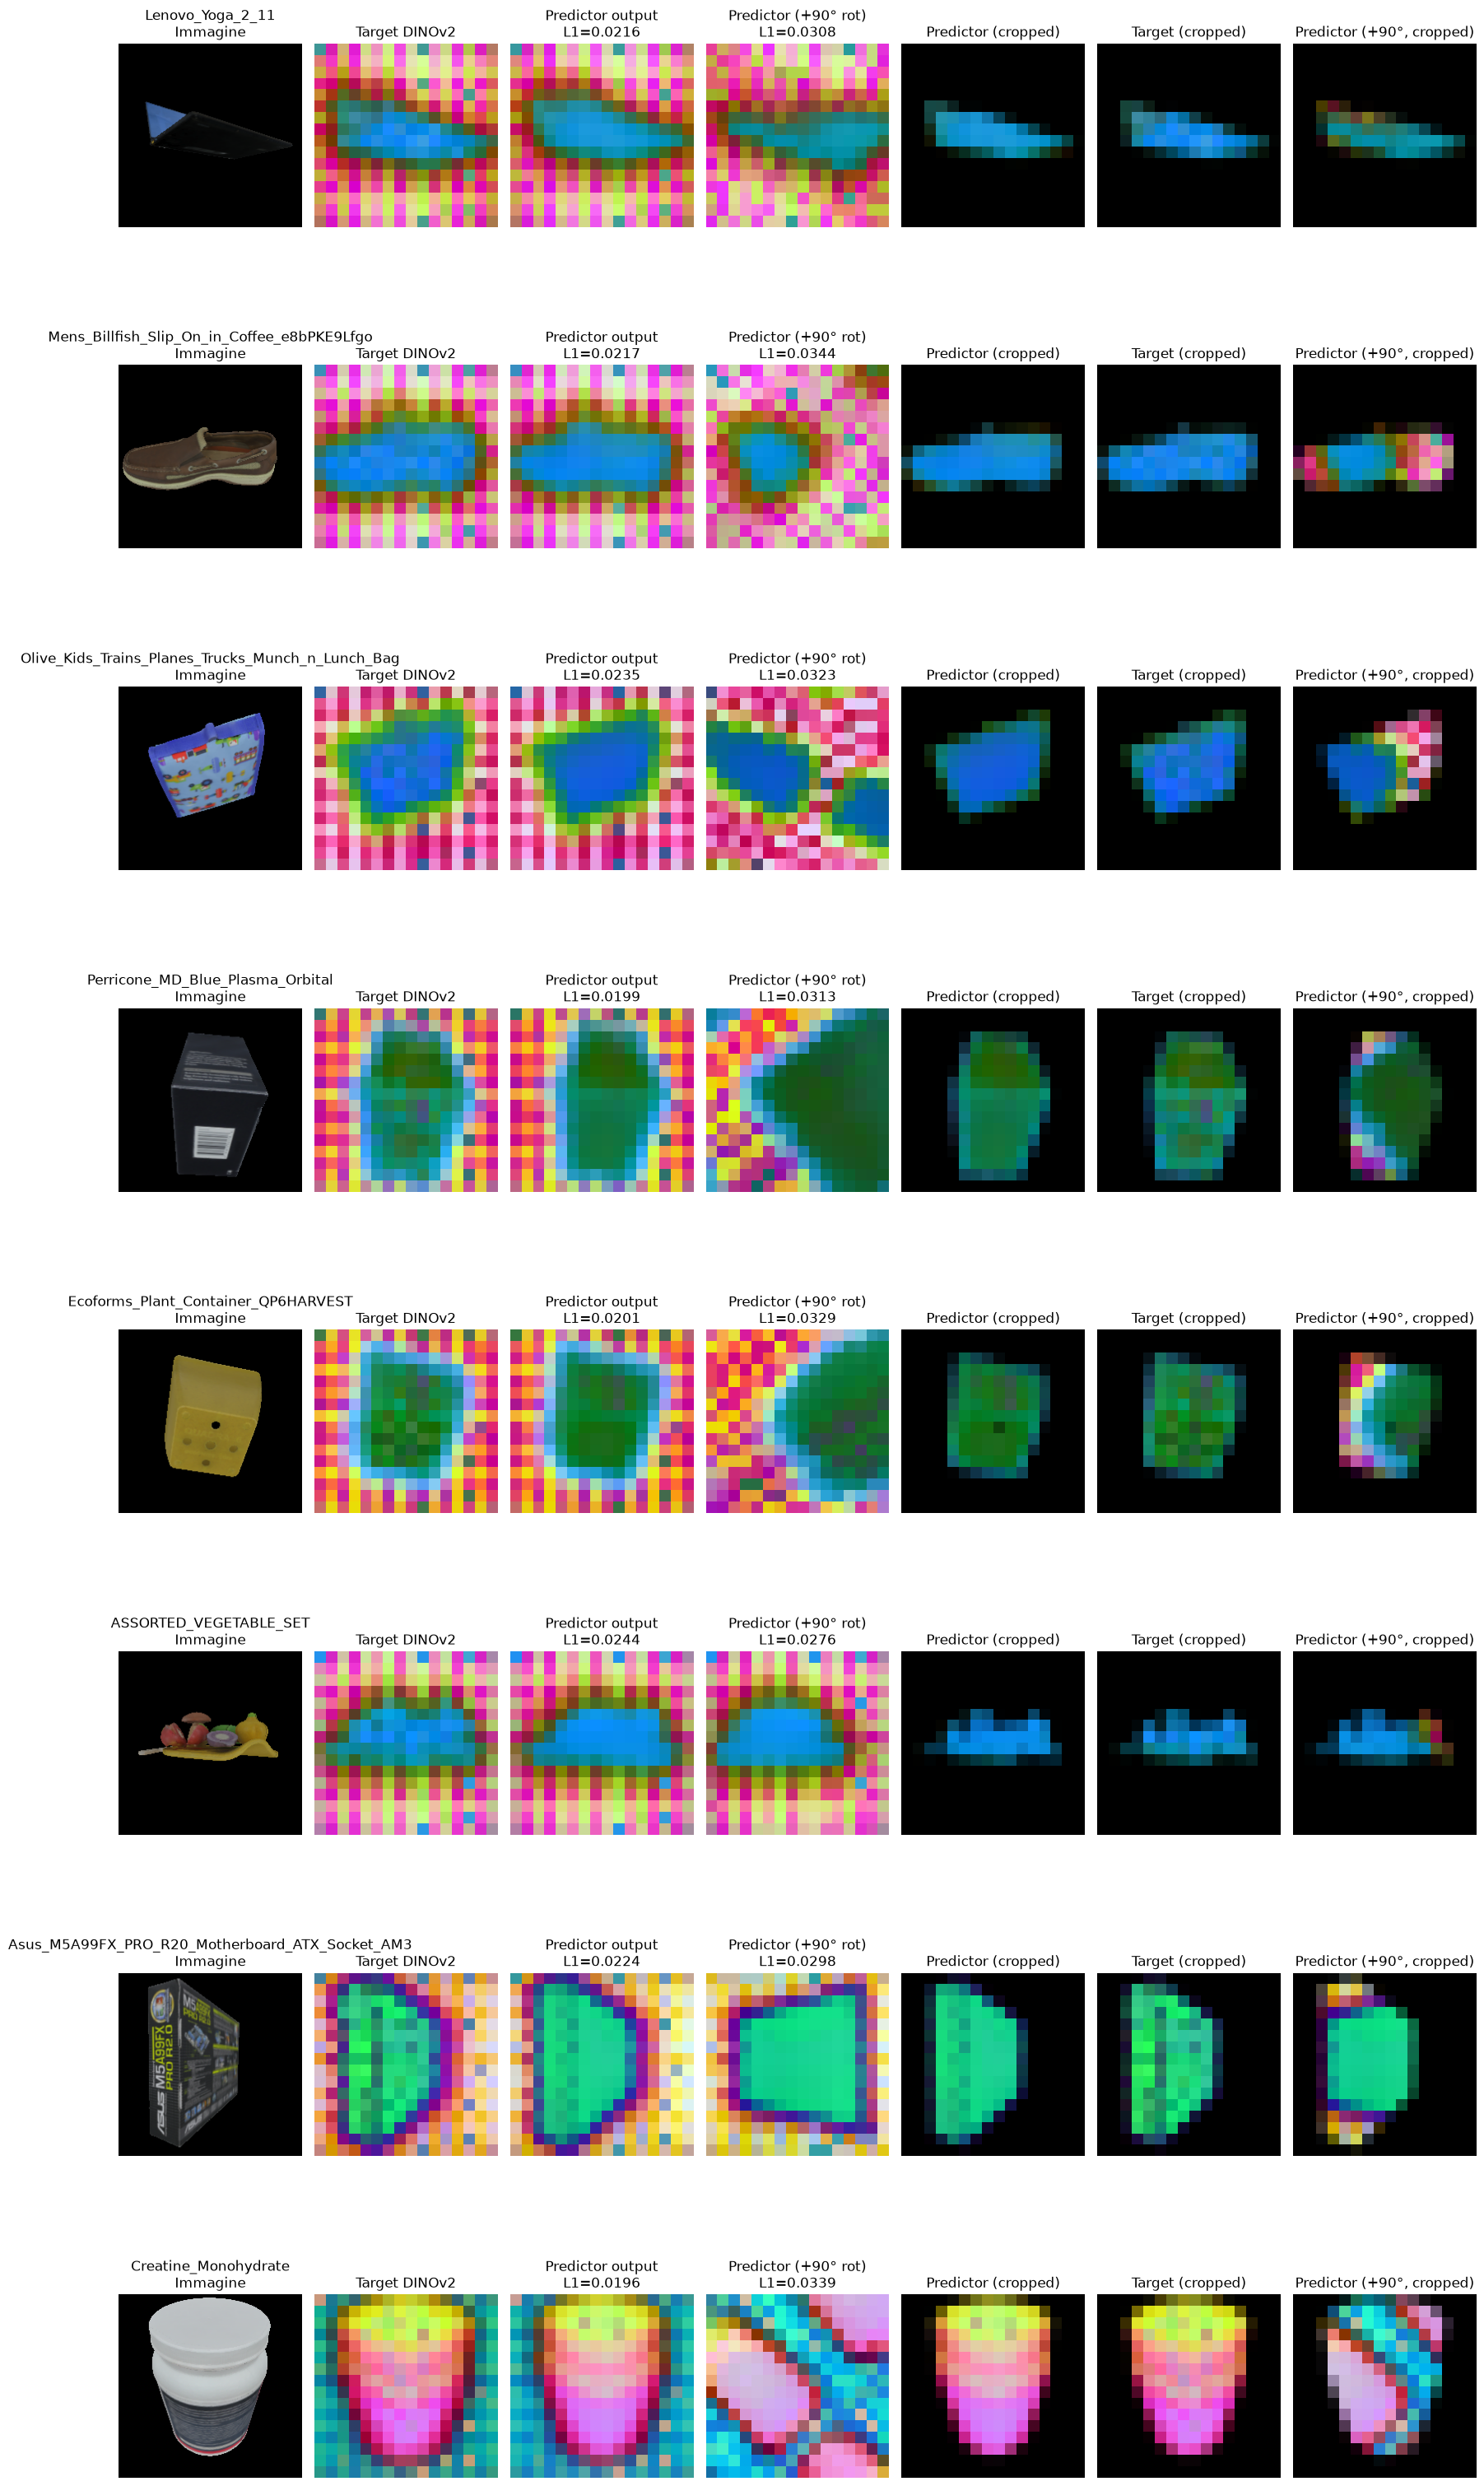

In [55]:
# =========================
# Visualizzazione target vs predictor su sample reali dal batch
# =========================
batch = next(sample_iter)
actual_bs = batch['image'].shape[0]


N_SHOW = min(8, actual_bs)
WRONG_ROT_DEG = 90.0
R_offset = rotation_matrix('y', WRONG_ROT_DEG, device)  # riusa da Cell 9

fig, axes = plt.subplots(N_SHOW, 7, figsize=(16.8, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    img_i = batch['image'][i].unsqueeze(0).to(device).float()   # (1,3,H,W)
    mask_i = batch['mask'][i].to(device).float()                 # (H,W)

    # --- Auto-detect: immagine gia' normalizzata (mean/std) o raw [0,1]? ---
    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i  # gia' normalizzata dal dataset

    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()   # world-to-camera
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)

    # --- context 3D e normalizzazione geometrica: gia' pronti dal dataset ---
    context_t = batch['context_3d'][i].unsqueeze(0).to(device).float()
    centers_t = batch['center_3d'][i].unsqueeze(0).to(device).float()
    centroid_t = batch['centroid'][i].unsqueeze(0).to(device).float()
    scale_t = batch['scale'][i].unsqueeze(0).to(device).float()

    ray_dirs, moment_c = _generate_rays(K_t, rot_t, trans_t, centroid_t, scale_t)
    ray_dirs_wrong, moment_wrong = _generate_rays(K_t, rot_wrong_t, trans_t, centroid_t, scale_t)

    # --- mask a livello di token (16x16) ---
    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)  # da Cell 8
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()  # (1, N)

    with torch.no_grad():
        target = encoder2d(img_t)
        pred = predictor(ray_dirs=ray_dirs, ray_moments=moment_c,
                          context_features=context_t, context_centers=centers_t)
        pred_wrong = predictor(ray_dirs=ray_dirs_wrong, ray_moments=moment_wrong,
                                context_features=context_t, context_centers=centers_t)

        # --- L1 mascherata (sull'embedding pieno, non sulla PCA) ---
        l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
        l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()

    target_np = target.squeeze(0).cpu().numpy()
    pred_np = pred.squeeze(0).cpu().numpy()
    pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    pred_pca = pca.transform(pred_np)
    pred_wrong_pca = pca.transform(pred_wrong_np)

    target_map = to_rgb_map_local(target_pca)
    pred_map = to_rgb_map_local(pred_pca)
    pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    print(f"{model_name}: L1 pred={l1_pred:.4f} | L1 pred(+{WRONG_ROT_DEG:.0f}°)={l1_pred_wrong:.4f}")

    axes[i, 0].imshow(bg_img); axes[i, 0].set_title(f"{model_name}\nImmagine"); axes[i, 0].axis('off')
    axes[i, 1].imshow(target_map); axes[i, 1].set_title("Target DINOv2"); axes[i, 1].axis('off')
    axes[i, 2].imshow(pred_map); axes[i, 2].set_title(f"Predictor output\nL1={l1_pred:.4f}"); axes[i, 2].axis('off')
    axes[i, 3].imshow(pred_wrong_map); axes[i, 3].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot)\nL1={l1_pred_wrong:.4f}"); axes[i, 3].axis('off')
    axes[i, 4].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 4].set_title("Predictor (cropped)"); axes[i, 4].axis('off')
    axes[i, 5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 5].set_title("Target (cropped)"); axes[i, 5].axis('off')
    axes[i, 6].imshow(pred_wrong_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 6].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}°, cropped)"); axes[i, 6].axis('off')

plt.tight_layout()
plt.show()

Womens_Sequin_Bahama_in_White_Sequin_yGVsSA4tOwJ: | Vera posa L1=0.0215 | +25° L1=0.0275 | +50° L1=0.0317 | +75° L1=0.0338 | +90° L1=0.0341 | +120° L1=0.0341 | +150° L1=0.0340 | +180° L1=0.0346
Toysmith_Windem_Up_Flippin_Animals_Dog: | Vera posa L1=0.0273 | +25° L1=0.0286 | +50° L1=0.0298 | +75° L1=0.0300 | +90° L1=0.0303 | +120° L1=0.0303 | +150° L1=0.0305 | +180° L1=0.0305
Hasbro_Monopoly_Hotels_Game: | Vera posa L1=0.0259 | +25° L1=0.0274 | +50° L1=0.0293 | +75° L1=0.0304 | +90° L1=0.0309 | +120° L1=0.0331 | +150° L1=0.0338 | +180° L1=0.0321
Melissa_Doug_Chunky_Puzzle_Vehicles: | Vera posa L1=0.0206 | +25° L1=0.0261 | +50° L1=0.0297 | +75° L1=0.0320 | +90° L1=0.0338 | +120° L1=0.0328 | +150° L1=0.0321 | +180° L1=0.0314
Grreatv_Choice_Dog_Bowl_Gray_Bones_Plastic_20_fl_oz_total: | Vera posa L1=0.0261 | +25° L1=0.0262 | +50° L1=0.0285 | +75° L1=0.0297 | +90° L1=0.0304 | +120° L1=0.0316 | +150° L1=0.0318 | +180° L1=0.0317
Nickelodeon_The_Spongebob_Movie_PopAPart_Spongebob: | Vera posa L

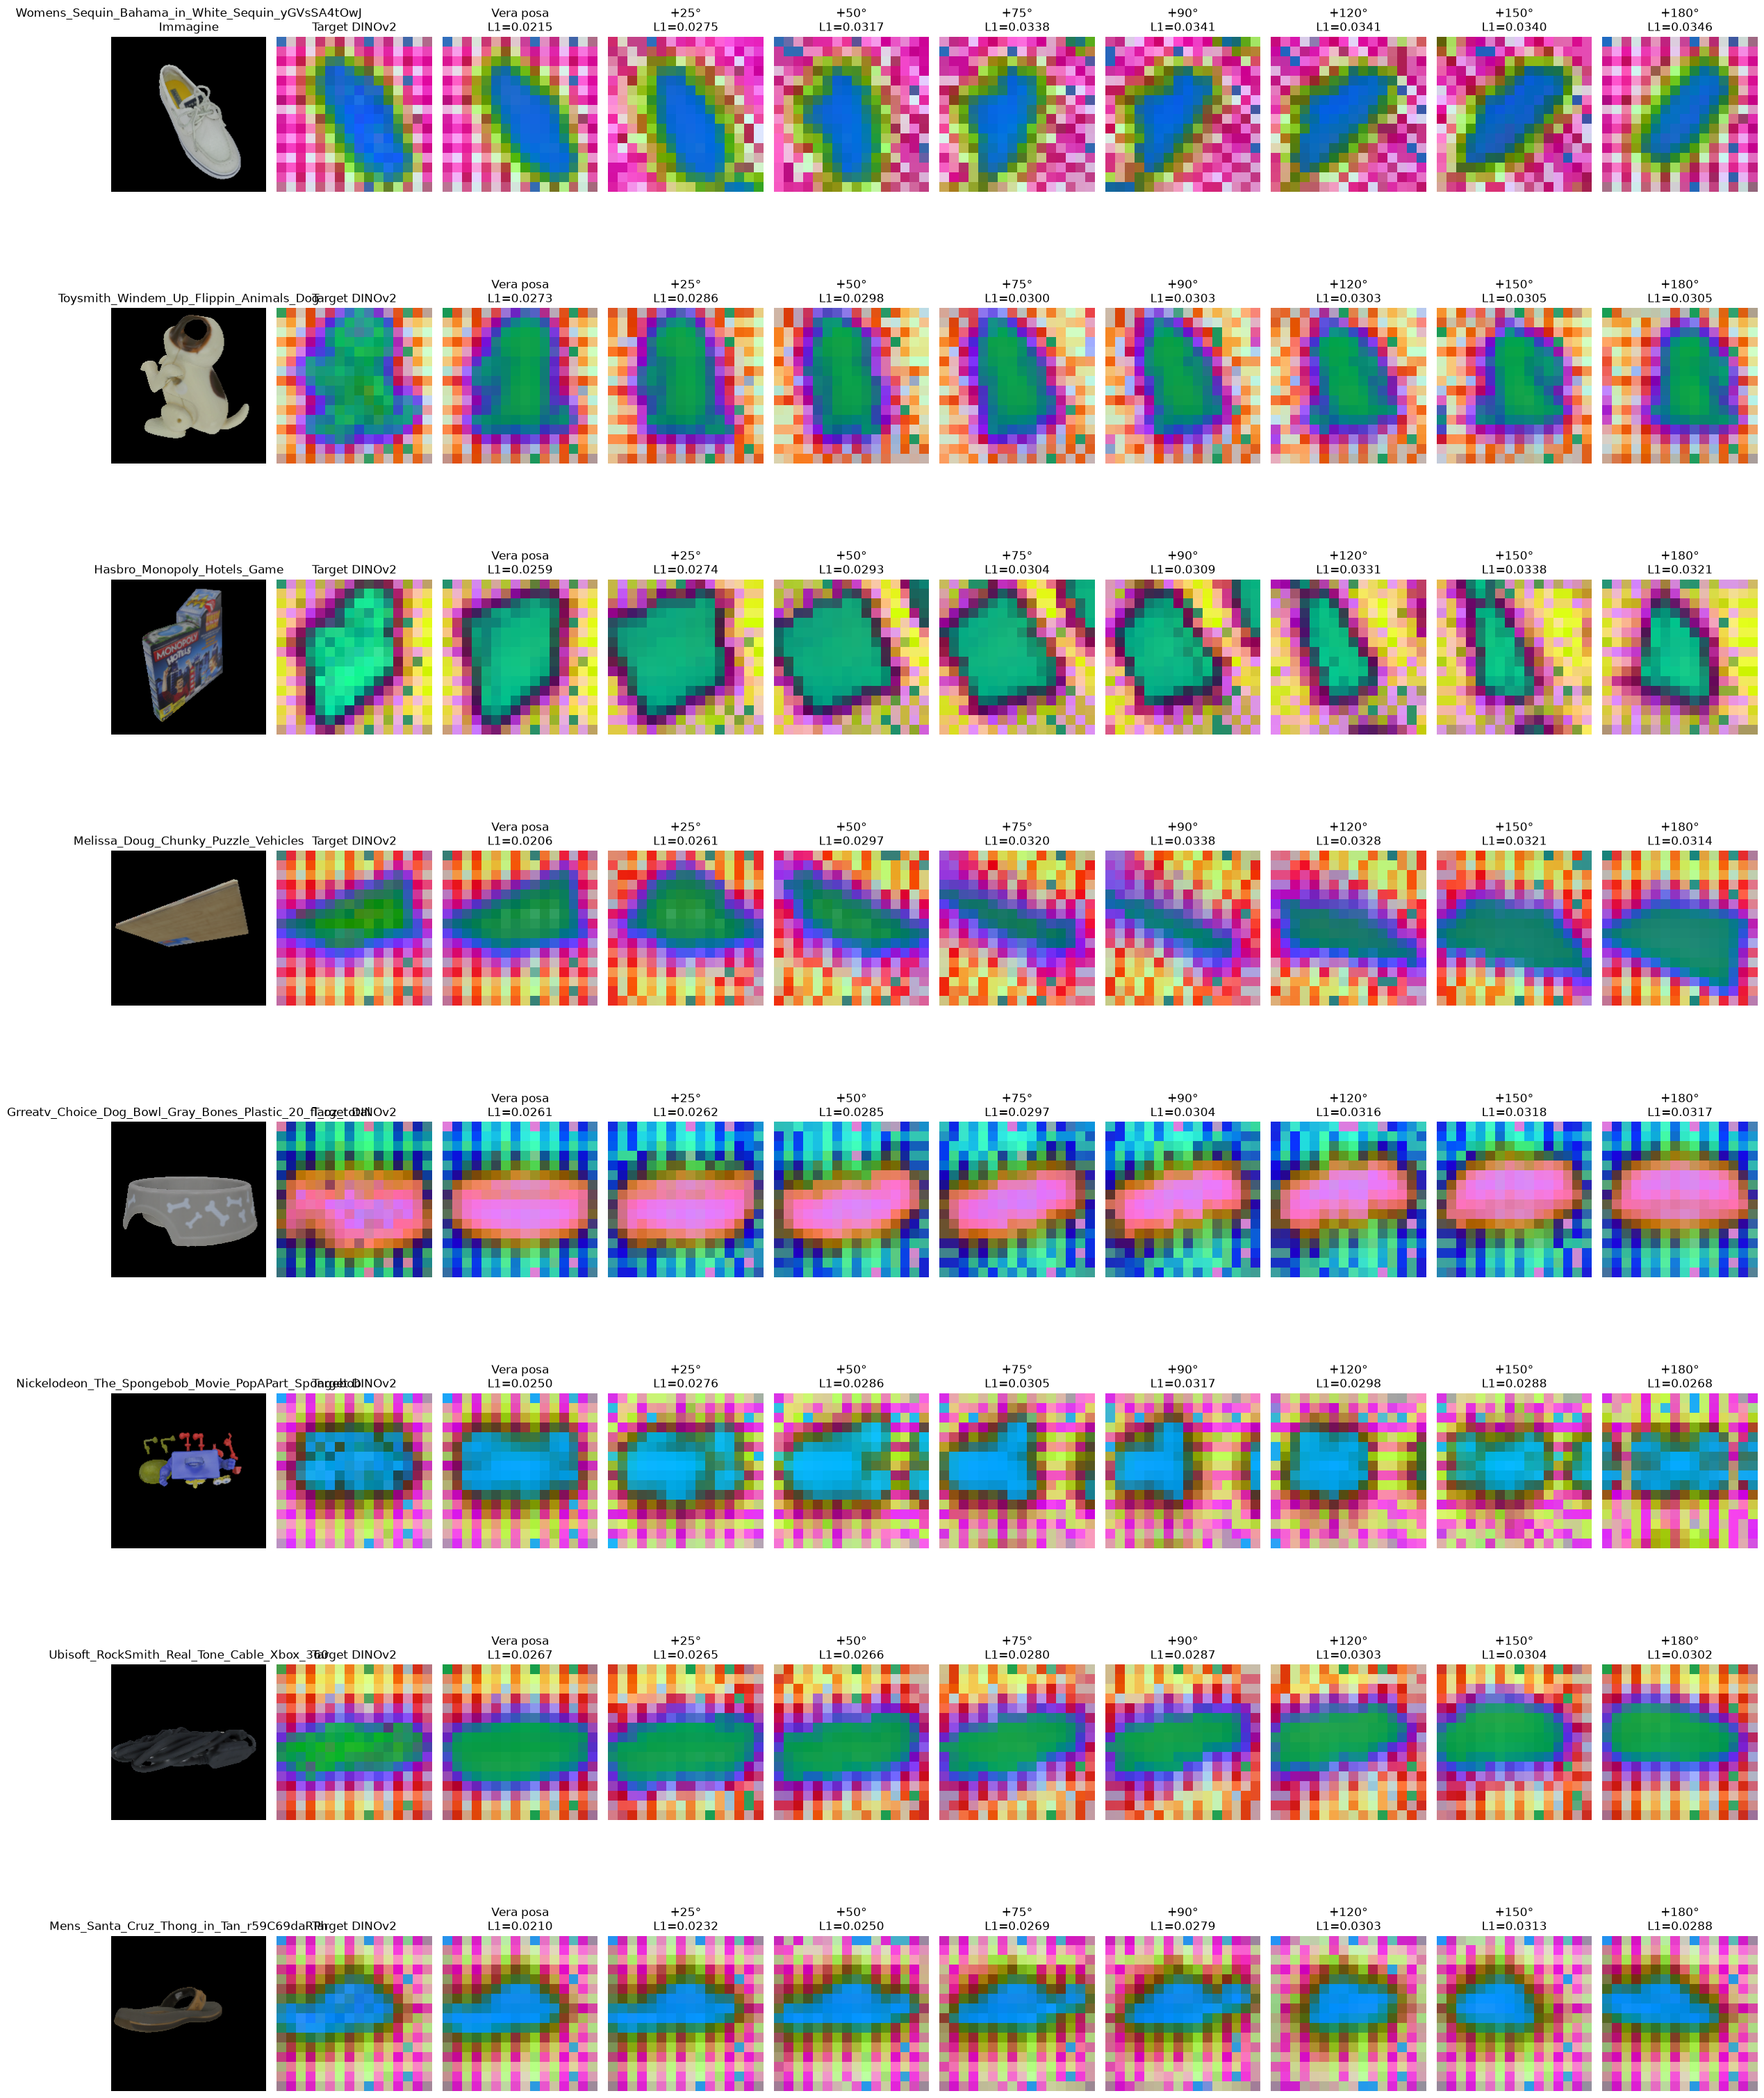

In [27]:
# =========================
# Visualizzazione target vs predictor su sample reali dal batch
# Vera posa + N rotazioni errate (multipli di 25°)
# =========================
batch = next(sample_iter)
actual_bs = batch['image'].shape[0]

N_SHOW = min(8, actual_bs)

# Lista delle rotazioni da testare: 0 = posa vera, poi offset crescenti
ROT_OFFSETS_DEG = [0.0, 25.0, 50.0, 75.0, 90, 120, 150, 180]
ROT_AXIS = 'y'
ROT_LABELS = ["Vera posa"] + [f"+{d:.0f}°" for d in ROT_OFFSETS_DEG[1:]]

R_offsets = [rotation_matrix(ROT_AXIS, d, device).unsqueeze(0).float() for d in ROT_OFFSETS_DEG]

N_COLS = 2 + len(ROT_OFFSETS_DEG)   # Immagine + Target + una colonna per ogni rotazione
fig, axes = plt.subplots(N_SHOW, N_COLS, figsize=(2.4 * N_COLS, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    img_i = batch['image'][i].unsqueeze(0).to(device).float()
    mask_i = batch['mask'][i].to(device).float()

    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i

    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    context_t = batch['context_3d'][i].unsqueeze(0).to(device).float()
    centers_t = batch['center_3d'][i].unsqueeze(0).to(device).float()
    centroid_t = batch['centroid'][i].unsqueeze(0).to(device).float()
    scale_t = batch['scale'][i].unsqueeze(0).to(device).float()

    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    with torch.no_grad():
        target = encoder2d(img_t)
        target_np = target.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    # --- immagine di sfondo ---
    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"{model_name}\nImmagine" if i == 0 else model_name)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    print_str = f"{model_name}:"

    # --- una colonna per ogni rotazione ---
    for j, (R_off, label) in enumerate(zip(R_offsets, ROT_LABELS)):
        rot_j = torch.matmul(R_off, rot_t)  # se j==0, R_off è identità -> posa vera
        ray_dirs, moment = _generate_rays(K_t, rot_j, trans_t, centroid_t, scale_t)

        with torch.no_grad():
            pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                              context_features=context_t, context_centers=centers_t)
            l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()

        pred_np = pred.squeeze(0).cpu().numpy()
        pred_pca = pca.transform(pred_np)          # stessa PCA del target
        pred_map = to_rgb_map_local(pred_pca)

        col = 2 + j
        axes[i, col].imshow(pred_map)
        axes[i, col].set_title(f"{label}\nL1={l1_pred:.4f}")
        axes[i, col].axis('off')

        print_str += f" | {label} L1={l1_pred:.4f}"

    print(print_str)

plt.tight_layout()
plt.show()